# Single-cell ATAC-seq part 1: quality control and preprocessing

**Case study: Can liver cell types and hepatocyte zonation be recovered from chromatin accessibility alone?**

Bravo González-Blas C, et al. *Single-cell spatial multi-omics and deep learning dissect enhancer-driven gene regulatory networks in liver zonation.* Nature Cell Biology (2024). https://doi.org/10.1038/s41556-023-01316-4

**Research questions:**

1. Can the cell types of the liver be recovered from accessibility alone, without RNA?
2. Is hepatocyte zonation (periportal versus pericentral) visible in the chromatin?
3. Which regions differ between pericentral and periportal hepatocytes, and are they near known zonated genes?

This notebook prepares the data; [part 2](part_2_pycistopic.ipynb) and [part 3](part_3_snapatac2.ipynb) answer questions 1 and 2 with two different tools, and [part 4](part_4_dars.ipynb) answers question 3 and ends with a conclusion.

## Introduction

Bulk ATAC-seq measures the average accessibility of millions of cells. A tissue like the liver is a mixture: hepatocytes make up most of its mass, but it also contains endothelial cells, stellate cells, Kupffer cells (liver macrophages), cholangiocytes and immune cells. Even hepatocytes are not all alike: depending on their position in the liver lobule they specialise in different metabolic tasks (**zonation**). Single-cell ATAC-seq (scATAC-seq) measures accessibility in each cell separately.

In droplet-based scATAC-seq (10x Genomics), nuclei are tagmented in bulk, then each nucleus is captured in a droplet with a gel bead carrying a unique **cell barcode**. All fragments from one nucleus get the same barcode. The data per cell are extremely sparse: a few thousand to tens of thousands of fragments per cell, so any single region has 0, 1 or 2 fragments. Single-cell analysis therefore always combines information across many cells and many regions.

The standard intermediate file is the **fragment file**: one line per unique fragment with its position and cell barcode. Everything in this notebook starts from it.

### The data

We use two samples of the [Bravo González-Blas et al., 2024](https://www.nature.com/articles/s41556-023-01316-4) liver study ([GEO GSE218468](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE218468)): mouse livers profiled with **10x Multiome**, which measures ATAC and RNA in the same nucleus. The two samples were prepared with different nuclei isolation protocols (the 10x protocol and the NST protocol), so we will also see a technical **batch effect**. Cell types were annotated in the paper using the RNA of the same cells, which gives us reliable labels to check our ATAC analysis. The [single-nucleus RNA-seq practical](../single-nucleus-rna-seq/index.md) analyses single-nucleus RNA-seq data of the same study, with the same cell types and zonation markers.

### Plan

1. read the fragment files;
2. compute per-cell quality metrics: number of fragments, TSS enrichment, fragment sizes;
3. select good cells and look for doublets;
4. add the cell-type and zonation annotations and check them with marker genes;
5. call peaks per cell type (**pseudobulk**) and build a **consensus peak set**, as in [part 2 of the bulk ATAC-seq practical](../bulk-atac-seq/part_2_consensus_peaks_macs_diff.ipynb);
6. build the cell × peak matrix used in the next notebooks: pycisTopic ([part 2](part_2_pycistopic.ipynb)), SnapATAC2 ([part 3](part_3_snapatac2.ipynb)) and differential accessibility ([part 4](part_4_dars.ipynb)).

We use [SnapATAC2](https://kzhang.org/SnapATAC2/) (Zhang et al., *Nature Methods* 2024), which reads fragment files quickly and stores the data on disk.

## Step 0: Setup

All four notebooks of this practical use one mamba environment with SnapATAC2, pycisTopic, scanpy and MACS3, described in `envs/atac-sc.yml` (it pins a few package versions that pycisTopic and SnapATAC2 need to work together). Create it once and register it as a Jupyter kernel, in a terminal (not in this notebook), from the folder of this notebook:

```
mamba env create -f envs/atac-sc.yml
mamba activate atac-sc
python -m ipykernel install --user --name atac-sc --display-name "Python (atac-sc)"
jupyter kernelspec list   # the kernel atac-sc should be listed
```

Then (re)start Jupyter and select the kernel "Python (atac-sc)".

The data (fragment files, cell annotations, a few mm10 annotation files, pre-generated results and the Mallet topic-modelling software) are in the folder `data` next to this notebook; the topic page explains how to rebuild them with the scripts in `scripts/`. Our results go to `data/results/part_1`.

In [1]:
%matplotlib inline
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import snapatac2 as snap

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 80

# The folder of this notebook (the kernel starts there). Kept when you run this cell again after os.chdir below.
HERE = globals().get("HERE", os.getcwd())

# Input data, in the folder data next to this notebook
SC = f"{HERE}/data"
GENOME = f"{SC}/genome"

# Your own results
OUT = f"{SC}/results/part_1"
os.makedirs(OUT, exist_ok=True)
os.chdir(OUT)

N_JOBS = 4
SAMPLES = {"Mouse_4_10x": f"{SC}/fragments/Mouse_4_10x.fragments.tsv.gz",
           "Mouse_5_NST": f"{SC}/fragments/Mouse_5_NST.fragments.tsv.gz"}
GTF = f"{GENOME}/gencode.vM25.annotation.gtf.gz"
chrom_sizes = pd.read_csv(f"{GENOME}/mm10.chrom.sizes", sep="\t", header=None, index_col=0)[1]
chrom_sizes = chrom_sizes[~chrom_sizes.index.str.contains("_")].to_dict()  # main chromosomes only
print("snapatac2", snap.__version__, "| results in", os.path.relpath(OUT, HERE))

snapatac2 2.8.0 | results in data/results/part_1


## Step 1: The fragment files

Each line of a fragment file is one unique Tn5 fragment: chromosome, start, end, **cell barcode**, and how many times this fragment was sequenced (PCR duplicates are collapsed into this count). The files were produced by `cellranger-arc`, 10x Genomics' pipeline, which also aligned the reads. They are sorted by position, compressed with `bgzip` and indexed with `tabix`, so tools can jump to any region.

The fragment files are already in `data/fragments`. They come from GEO and were prepared with the code below (also in `scripts/01_download_sc.sh`). It is shown as text, **don't run it**: the files are about 3.3 GB and recompressing them takes a while. GEO stores them with plain `gzip`, but `tabix` needs `bgzip` (block-compressed) files.

```bash
mkdir -p data/raw data/fragments && cd data/raw
URL=https://ftp.ncbi.nlm.nih.gov/geo/series/GSE218nnn/GSE218468/suppl
wget $URL/GSE218468_TEW_043783_523d9c_Multiome_Liver_10xprotocol_fragments.tsv.gz       # Mouse_4, 10x protocol
wget $URL/GSE218468_TEW_ebb273_b33e6f_Multiome_Liver_CTRL_NSTprotocol_fragments.tsv.gz  # Mouse_5, NST protocol
# recompress with bgzip under a short name, then index with tabix (-p bed: the file is BED-like)
zcat GSE218468_TEW_043783_523d9c_Multiome_Liver_10xprotocol_fragments.tsv.gz | bgzip > ../fragments/Mouse_4_10x.fragments.tsv.gz
zcat GSE218468_TEW_ebb273_b33e6f_Multiome_Liver_CTRL_NSTprotocol_fragments.tsv.gz | bgzip > ../fragments/Mouse_5_NST.fragments.tsv.gz
tabix -p bed ../fragments/Mouse_4_10x.fragments.tsv.gz
tabix -p bed ../fragments/Mouse_5_NST.fragments.tsv.gz
```

Let's look at the first lines of one file:

In [2]:
# the first 5 lines; comment="#" skips the header lines that start with #
pd.read_csv(SAMPLES["Mouse_5_NST"], sep="\t", header=None, comment="#", nrows=5,
            names=["chrom", "start", "end", "barcode", "count"])

,chrom,start,end,barcode,count
0,chr1,3000025,3000092,GTAATAGCACCTAAGC-1,1
1,chr1,3000267,3000463,CACAAGCGTGTTGTGA-1,1
2,chr1,3000296,3000519,GGACATAAGCAACATC-1,2
3,chr1,3000319,3000373,GATTACGGTTGCTTCG-1,2
4,chr1,3000379,3000657,CCTGCTCCATAATCGT-1,2


## Step 2: Importing the fragments

`snap.pp.import_fragments` reads a fragment file and creates an AnnData object with **one row per barcode**. We only keep barcodes with at least 200 fragments; most other barcodes are empty droplets with a little ambient DNA. With `file=...` the data are stored in an `.h5ad` file on disk instead of in memory ("backed" mode), which keeps memory use low.

This takes about 10 minutes for the two samples.

In [3]:
adatas = {}
for name, fragments in SAMPLES.items():
    # sorted_by_barcode=False: the file is sorted by position; min_num_fragments: drop barcodes with fewer fragments
    adatas[name] = snap.pp.import_fragments(
        fragments, chrom_sizes=chrom_sizes, file=f"{name}.h5ad",
        sorted_by_barcode=False, min_num_fragments=200, n_jobs=N_JOBS)
    print(name, adatas[name].n_obs, "barcodes")
adatas["Mouse_5_NST"]

Mouse_4_10x 19444 barcodes
Mouse_5_NST 9075 barcodes


AnnData object with n_obs x n_vars = 9075 x 0 backed at 'Mouse_5_NST.h5ad'
    obs: 'n_fragment', 'frac_dup', 'frac_mito'
    uns: 'reference_sequences'
    obsm: 'fragment_paired'

*If the import takes too long, copy the pre-generated files instead and reopen them: `cp $SC/data_generated/Mouse_*.h5ad .` in a terminal, then `adatas = {n: snap.read(f"{n}.h5ad") for n in SAMPLES}`.*

The objects have one row per barcode and no columns yet (`n_vars = 0`): the fragments themselves are stored in `obsm["fragment_paired"]`, and per-barcode statistics in `obs`:

- `n_fragment`: number of unique fragments;
- `frac_dup`: fraction of duplicate reads (from the count column of the fragment file);
- `frac_mito`: fraction of mitochondrial fragments. It is 0 here because `cellranger-arc` leaves chrM out of the fragment file.

Because the data live on disk, `obs` is read with `[:]` and returned as a [polars](https://pola.rs/) table. A small helper converts it to a pandas table with the barcodes as index:

In [4]:
def obs_df(adata):
    """Per-barcode table of a (backed) SnapATAC2 AnnData as pandas."""
    return adata.obs[:].to_pandas().set_index(pd.Index(adata.obs_names, name="barcode"))

obs_df(adatas["Mouse_5_NST"]).describe().round(3)

,n_fragment,frac_dup,frac_mito
count,9075.000,9075.000,9075.0
mean,7930.880,0.387,0.0
std,13069.607,0.040,0.0
min,200.000,0.004,0.0
25%,783.000,0.369,0.0
50%,5048.000,0.393,0.0
75%,10896.500,0.409,0.0
max,322532.000,0.929,0.0


## Step 3: Quality control

### 3a. Fragment size distribution and TSS enrichment

These are the same two ATAC hallmarks as in bulk ([part 1 of the bulk ATAC-seq practical](../bulk-atac-seq/part_1_reads_to_peaks.ipynb)), but now **per cell** for TSS enrichment: SnapATAC2 computes, for each barcode, the signal at TSSs (from the GENCODE annotation) relative to the flanks.

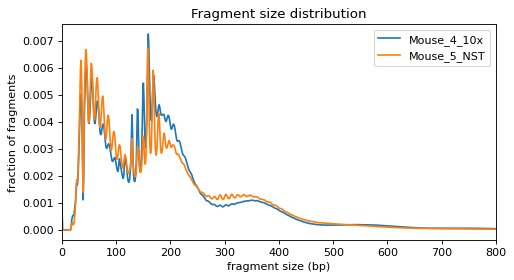

In [5]:
for name, adata in adatas.items():
    snap.metrics.frag_size_distr(adata, max_recorded_size=1000)  # stored in adata.uns["frag_size_distr"]
    snap.metrics.tsse(adata, GTF)                                # TSS enrichment per barcode, stored in obs["tsse"]

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, adata in adatas.items():
    sizes = np.asarray(adata.uns["frag_size_distr"])
    ax.plot(np.arange(len(sizes)), sizes / sizes.sum(), label=name)
ax.set(xlabel="fragment size (bp)", ylabel="fraction of fragments", xlim=(0, 800), title="Fragment size distribution")
ax.legend()
plt.show()

Both samples show the 10 bp ripples on short fragments, the mono-nucleosome peak around 180-200 bp and a weaker di-nucleosome shoulder: good libraries.

### 3b. Selecting cells

Real cells have **many fragments** and a **high TSS enrichment**. Barcodes with few fragments are empty droplets or broken nuclei; barcodes with many fragments but a low TSS enrichment are dead or damaged cells whose fragments fall everywhere. Plotting the two metrics against each other shows the population of good cells:

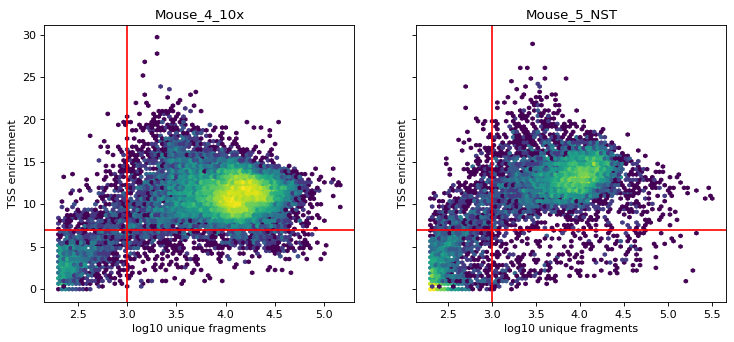

In [6]:
MIN_FRAGMENTS = 1000
MIN_TSSE = 7

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (name, adata) in zip(axes, adatas.items()):
    qc = obs_df(adata)
    # hexbin: a 2D histogram (colour = number of barcodes, on a log scale), better than a scatter plot for tens of thousands of points
    ax.hexbin(np.log10(qc["n_fragment"]), qc["tsse"], gridsize=80, bins="log", cmap="viridis", mincnt=1)
    ax.axvline(np.log10(MIN_FRAGMENTS), color="red")
    ax.axhline(MIN_TSSE, color="red")
    ax.set(title=name, xlabel="log10 unique fragments", ylabel="TSS enrichment")
plt.show()

How many barcodes pass these thresholds? The authors of the paper selected cells with their own QC (pycisTopic, plus the RNA of the same nuclei). Their list of cells is in `annotations/paper_cells.tsv`; let's compare:

In [7]:
paper_cells = pd.read_csv(f"{SC}/annotations/paper_cells.tsv", sep="\t")

for name, adata in adatas.items():
    qc = obs_df(adata)
    # sets of barcodes, so we can intersect them with &
    ours = set(qc.index[(qc["n_fragment"] >= MIN_FRAGMENTS) & (qc["tsse"] >= MIN_TSSE)])
    theirs = set(paper_cells.loc[paper_cells["sample"] == name, "barcode"])
    print(f"{name}: we keep {len(ours)}, the paper kept {len(theirs)}, both: {len(ours & theirs)}")

Mouse_4_10x: we keep 16765, the paper kept 7518, both: 7301
Mouse_5_NST: we keep 6263, the paper kept 4173, both: 3996


We keep more barcodes than the paper, and almost all of the paper's cells are among ours. In a Multiome experiment a nucleus must also pass **RNA** quality control (enough genes and UMIs, few mitochondrial reads) to be called a cell, and the authors chose stricter ATAC thresholds as well. Thresholds are a choice: there is no single right value (Exercise 1 tries stricter ones).

We keep the permissive thresholds and filter the barcodes. `filter_cells` subsets the objects (and their files) in place:

In [9]:
for name, adata in adatas.items():
    # min_counts: minimum number of unique fragments; min_tsse: minimum TSS enrichment
    snap.pp.filter_cells(adata, min_counts=MIN_FRAGMENTS, min_tsse=MIN_TSSE)
    print(name, adata.n_obs, "cells")

Mouse_4_10x 16765 cells
Mouse_5_NST 6263 cells


### 3c. Doublets

Sometimes two nuclei end up in the same droplet and share a barcode. Such **doublets** look like a mixture of two cell types and can create artificial "intermediate" clusters. [Scrublet](https://github.com/swolock/scrublet) detects them by simulating doublets (adding up random pairs of cells) and flagging real cells that resemble the simulated ones.

Scrublet needs a cell × feature matrix. A simple, annotation-free choice for ATAC is a **tile matrix**: the genome cut into 500 bp bins, counting fragment insertions per cell and bin. We keep the 250,000 most accessible bins. This takes about 10 minutes.

In [10]:
for name, adata in adatas.items():
    snap.pp.add_tile_matrix(adata, bin_size=500)        # cell x 500 bp bin matrix
    snap.pp.select_features(adata, n_features=250000)   # keep the 250,000 most accessible bins
    snap.pp.scrublet(adata)                             # adds doublet_probability to obs
    qc = obs_df(adata)
    print(f"{name}: {qc['doublet_probability'].gt(0.5).sum()} of {adata.n_obs} cells are likely doublets")

Mouse_4_10x: 2899 of 16765 cells are likely doublets
Mouse_5_NST: 782 of 6263 cells are likely doublets


2026-10-27 23:11:41 - INFO - Selected 250000 features.
2026-10-27 23:12:01 - INFO - Simulating doublets...
2026-10-27 23:12:03 - INFO - Spectral embedding ...
2026-10-27 23:18:09 - INFO - Calculating doublet scores...
2026-10-27 23:18:42 - INFO - Selected 250000 features.
2026-10-27 23:18:47 - INFO - Simulating doublets...
2026-10-27 23:18:48 - INFO - Spectral embedding ...
2026-10-27 23:20:45 - INFO - Calculating doublet scores...


Doublets tend to have more fragments than single cells (two nuclei!). Let's check that, and how many of the cells kept by the paper are flagged:

In [11]:
for name, adata in adatas.items():
    qc = obs_df(adata)
    is_doublet = qc["doublet_probability"] > 0.5
    in_paper = qc.index.isin(paper_cells.loc[paper_cells["sample"] == name, "barcode"])
    print(f"{name}: median fragments singlets {qc.loc[~is_doublet, 'n_fragment'].median():.0f}, "
          f"doublets {qc.loc[is_doublet, 'n_fragment'].median():.0f}; "
          f"{(is_doublet & in_paper).sum()} of the paper's {in_paper.sum()} cells are flagged")

Mouse_4_10x: median fragments singlets 10660, doublets 27078; 1276 of the paper's 7301 cells are flagged
Mouse_5_NST: median fragments singlets 7392, doublets 22096; 212 of the paper's 3996 cells are flagged


Scrublet flags a surprisingly large number of cells that the paper kept. We will see in the next section **which** cells these are before deciding what to remove.

## Step 4: Cell-type and zonation annotations

The authors annotated these nuclei using their **RNA** profiles (the other half of the Multiome measurement), and assigned each hepatocyte a **zone** along the axis from the portal vein (**periportal, PP**) to the central vein (**pericentral, PC**). We load these labels from `annotations/cell_annotations.tsv`:

- `cell_type`: the RNA-based cell type;
- `zone`: `PP`, `mid` or `PC` for hepatocytes (empty for other cell types).

In [12]:
annotations = pd.read_csv(f"{SC}/annotations/cell_annotations.tsv", sep="\t")
print(annotations.head())

# reindex: look up each of our barcodes in the annotation table (NaN if it is not there)
for name, adata in adatas.items():
    labels = annotations[annotations["sample"] == name].set_index("barcode")
    adata.obs["cell_type"] = labels["cell_type"].reindex(adata.obs_names).fillna("unannotated").tolist()
    adata.obs["zone"] = labels["zone"].reindex(adata.obs_names).fillna("").tolist()
    adata.obs["sample"] = [name] * adata.n_obs

pd.concat({name: obs_df(adata)["cell_type"].value_counts() for name, adata in adatas.items()}, axis=1).fillna(0).astype(int)

              barcode       sample   cell_type cell_type_fine cell_type_atac  \
0  AAACAGCCAAGGAATC-1  Mouse_4_10x  Hepatocyte    Hep_PP_PC_1    Hep_PP_PC_1   
1  AAACATGCACCATATG-1  Mouse_4_10x  Hepatocyte    Hep_PP_PC_4    Hep_PP_PC_3   
2  AAACATGCAGGATGGC-1  Mouse_4_10x  Hepatocyte    Hep_PP_PC_5    Hep_PP_PC_3   
3  AAACCAACAATAATGG-1  Mouse_4_10x        LSEC           LSEC           LSEC   
4  AAACCGAAGCTTAGTA-1  Mouse_4_10x  Hepatocyte    Hep_PP_PC_5    Hep_PP_PC_2   

  zone  
0   PP  
1   PC  
2   PC  
3  NaN  
4   PC  


,Mouse_4_10x,Mouse_5_NST
unannotated,9464,2267
Hepatocyte,6340,3549
LSEC,311,45
Kupffer,298,53
HSC,243,283
BEC,40,4
DC,21,14
VEC,15,3
T_cell,14,31
B_cell,8,3


Hepatocytes dominate, followed by stellate cells (HSC), endothelial cells (LSEC) and Kupffer cells. The `unannotated` barcodes passed our ATAC QC but not the authors' combined ATAC + RNA QC.

### Back to the doublets

Now that we know the cell types, let's see which cells Scrublet flags as doublets (`doublet_probability > 0.5`): the fraction of flagged cells per cell type, and their median number of fragments.

In [13]:
qc_all = pd.concat([obs_df(adata) for adata in adatas.values()])
qc_all["flagged"] = qc_all["doublet_probability"] > 0.5
# per cell type: number of cells, fraction flagged (the mean of True/False), median number of fragments
summary = qc_all.groupby("cell_type").agg(cells=("flagged", "size"), flagged=("flagged", "mean"),
                                           median_fragments=("n_fragment", "median"))
summary["flagged"] = (100 * summary["flagged"]).round(1)
summary.sort_values("cells", ascending=False)

,cells,flagged,median_fragments
cell_type,,,
unannotated,11731,18.7,11136.0
Hepatocyte,9889,14.7,12062.0
HSC,526,0.8,3178.5
LSEC,356,0.8,3944.5
Kupffer,351,1.1,5425.0
T_cell,45,6.7,4173.0
BEC,44,2.3,5321.0
DC,35,8.6,4220.0
VEC,18,22.2,3656.0


Among the main cell types, hepatocytes are flagged far more often (about 15%, against about 1% of stellate, endothelial and Kupffer cells), and they have about three times more fragments. (The high percentages of some rare cell types rest on a handful of cells.) Many hepatocyte nuclei are **polyploid** (4n, 8n): they contain more DNA, give more fragments, and look like the simulated doublets. A doublet detector based on ATAC alone cannot tell them apart from real doublets. Removing all flagged cells would deplete exactly the cells we are most interested in.

Here we are lucky: the authors removed doublets using both RNA and ATAC of the same nuclei. We therefore keep the cells that passed **our** ATAC QC and were **annotated** by the paper, and leave Scrublet's calls aside. In a dataset without such information, you would inspect flagged cells per cluster before removing them.

In [14]:
for name, adata in adatas.items():
    keep = (obs_df(adata)["cell_type"] != "unannotated").to_numpy()
    # subset by position (row numbers); this also rewrites the .h5ad file
    adata.subset(obs_indices=np.flatnonzero(keep))
    print(name, adata.n_obs, "cells kept")

Mouse_4_10x 7301 cells kept
Mouse_5_NST 3996 cells kept


### Checking the labels with gene activity

The labels come from RNA. Do they make sense in the ATAC data too? A simple proxy for expression from ATAC is **gene activity**: the number of fragments over a gene body plus its promoter. Accessible, active genes collect more fragments. `snap.pp.make_gene_matrix` builds a cell × gene matrix of these counts.

In [15]:
gene_activity = sc.concat([snap.pp.make_gene_matrix(adata, gene_anno=GTF) for adata in adatas.values()])
for col in ["cell_type", "zone", "sample"]:
    gene_activity.obs[col] = pd.concat([obs_df(adata)[col] for adata in adatas.values()]).values
# as for RNA: scale every cell to 10,000 counts, then log(1 + x)
sc.pp.normalize_total(gene_activity, target_sum=1e4)
sc.pp.log1p(gene_activity)
gene_activity

AnnData object with n_obs × n_vars = 11297 × 55291
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'tsse', 'doublet_probability', 'doublet_score', 'cell_type', 'zone', 'sample'
    uns: 'log1p'

A dot plot of classic markers: the colour is the mean gene activity per cell type, the dot size the fraction of cells with any activity. Each cell type should light up for its own markers.

... storing 'cell_type' as categorical
... storing 'zone' as categorical
... storing 'sample' as categorical


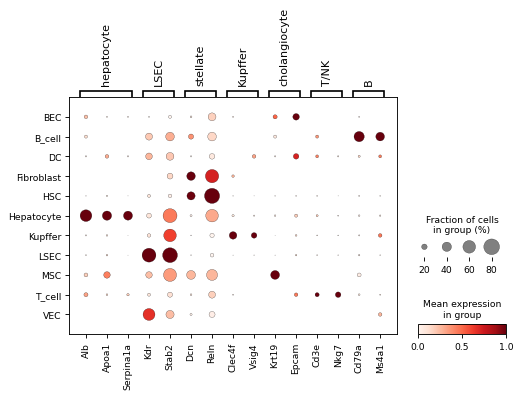

In [16]:
markers = {
    "hepatocyte": ["Alb", "Apoa1", "Serpina1a"],
    "LSEC": ["Kdr", "Stab2"],
    "stellate": ["Dcn", "Reln"],
    "Kupffer": ["Clec4f", "Vsig4"],
    "cholangiocyte": ["Krt19", "Epcam"],
    "T/NK": ["Cd3e", "Nkg7"],
    "B": ["Cd79a", "Ms4a1"],
}
# standard_scale="var": scale each gene from 0 to 1, so weakly and strongly active genes can be compared
sc.pl.dotplot(gene_activity, markers, groupby="cell_type", standard_scale="var", show=False)
plt.show()

The zone labels can be checked in the same way with the classic zonation markers; that is Exercise 2 at the end of this notebook.

## Step 5: Pseudobulk peaks and a consensus peak set

To build a cell × region matrix we need regions. Calling peaks on single cells is impossible (a few fragments per cell), so we **pool** the fragments of all cells of one group (a *pseudobulk*), call peaks per group with MACS3, and merge the groups into a consensus set. Calling per group, rather than on all cells together, keeps peaks of rare cell types that would be drowned out by the hepatocytes.

We call peaks per cell type, and split hepatocytes by zone so that zonated peaks are found too. First, both samples are combined into one `AnnDataSet` (a view over the two files, without copying them):

In [18]:
# collect the cell table first: the AnnDataSet takes over the two sample objects
cells = pd.concat([obs_df(adata) for adata in adatas.values()])
data = snap.AnnDataSet(adatas=[(name, adata) for name, adata in adatas.items()], filename="liver.h5ads")
for col in ["cell_type", "zone", "n_fragment", "tsse"]:
    data.obs[col] = cells[col].tolist()
# peak-calling groups: cell types, with hepatocytes split by zone
data.obs["peak_group"] = [f"Hepatocyte_{z}" if z else ct for ct, z in zip(cells["cell_type"], cells["zone"])]
data

AnnDataSet object with n_obs x n_vars = 11297 x 5267565 backed at 'liver.h5ads'
contains 2 AnnData objects with keys: 'Mouse_4_10x', 'Mouse_5_NST'
    obs: 'sample', 'cell_type', 'zone', 'n_fragment', 'tsse', 'peak_group'
    uns: 'AnnDataSet', 'reference_sequences'

`snap.tl.macs3` writes one pseudobulk per group and runs MACS3 on it (q < 0.05, excluding the blacklist). This takes 10-15 minutes. Groups with fewer than 40 cells are skipped: their pseudobulk is too small to call peaks reliably.

*If it takes too long: `peaks = {k: pl.read_parquet(f"{SC}/data_generated/pseudobulk_peaks/{k}.parquet") for k in ...}`, see the code in the next cell.*

In [19]:
import polars as pl

# only groups with enough cells give a useful pseudobulk
group_sizes = pd.Series(data.obs["peak_group"].to_list()).value_counts()
groups = sorted(group_sizes.index[group_sizes >= 40])
print("calling peaks for:", ", ".join(groups))
print("skipped (< 40 cells):", ", ".join(group_sizes.index[group_sizes < 40]))

pregenerated = f"{SC}/data_generated/pseudobulk_peaks"
USE_PREGENERATED = False  # set to True to skip peak calling

if USE_PREGENERATED:
    peaks = {f[:-8]: pl.read_parquet(f"{pregenerated}/{f}") for f in sorted(os.listdir(pregenerated))}
else:
    # one pseudobulk per value of peak_group; inplace=False returns the peaks as a dict of tables
    peaks = snap.tl.macs3(data, groupby="peak_group", selections=set(groups),
                          blacklist=f"{GENOME}/mm10-blacklist.v2.bed", n_jobs=N_JOBS, inplace=False)
    os.makedirs("pseudobulk_peaks", exist_ok=True)
    for group, df in peaks.items():
        df.write_parquet(f"pseudobulk_peaks/{group}.parquet")
pd.Series({group: df.height for group, df in peaks.items()}, name="peaks")

calling peaks for: BEC, HSC, Hepatocyte_PC, Hepatocyte_PP, Hepatocyte_mid, Kupffer, LSEC, T_cell
skipped (< 40 cells): DC, VEC, Fibroblast, B_cell, MSC


2026-10-27 23:23:09 - INFO - Exporting fragments...
2026-10-27 23:23:57 - INFO - Calling peaks...

  0%|          | 0/8 [00:00<?, ?it/s]

 12%|█▎        | 1/8 [00:08<00:56,  8.00s/it]

 25%|██▌       | 2/8 [00:08<00:21,  3.59s/it]

 38%|███▊      | 3/8 [00:39<01:20, 16.11s/it]

 50%|█████     | 4/8 [00:40<00:39,  9.95s/it]

 62%|██████▎   | 5/8 [01:05<00:46, 15.38s/it]

 75%|███████▌  | 6/8 [04:23<02:34, 77.49s/it]

 88%|████████▊ | 7/8 [07:14<01:48, 108.08s/it]

100%|██████████| 8/8 [11:09<00:00, 148.51s/it]

100%|██████████| 8/8 [11:09<00:00, 83.71s/it] 



HSC                58166
BEC                10856
Hepatocyte_mid    123354
T_cell             12113
Hepatocyte_PP     155188
Kupffer            49198
Hepatocyte_PC     141810
LSEC               42996
Name: peaks, dtype: int64

**Question**: Rare cell types (with few cells) get fewer peaks. Why? Is that a problem?

### Merging into a consensus

`snap.tl.merge_peaks` builds the consensus exactly like the fixed-width method of [part 2 of the bulk ATAC-seq practical](../bulk-atac-seq/part_2_consensus_peaks_macs_diff.ipynb): it extends each summit by 250 bp on both sides (501 bp, the summit included; we call them 500 bp peaks), and iteratively keeps the most significant one and removes the windows overlapping it. The result also records in which groups each peak was called.

In [20]:
# merge_peaks: 500 bp windows around the summits of all groups, selected iteratively (see the text above)
consensus = snap.tl.merge_peaks(peaks, chrom_sizes).to_pandas()
print(consensus.shape[0], "consensus peaks of 500 bp")
consensus.head()

203415 consensus peaks of 500 bp


,Peaks,HSC,Hepatocyte_PP,Hepatocyte_PC,LSEC,BEC,Hepatocyte_mid,Kupffer,T_cell
0,chr1:3121253-3121754,True,False,False,True,False,False,False,False
1,chr1:3251101-3251602,False,True,False,False,False,False,False,False
2,chr1:3368825-3369326,False,True,False,False,False,False,False,False
3,chr1:3416050-3416551,False,True,True,False,False,True,False,False
4,chr1:3423117-3423618,False,True,True,False,False,True,False,False


You should get about 203,000 consensus peaks. How many groups share each peak? Peaks found in every group are typically promoters of housekeeping genes; peaks found in one group are candidate cell-type-specific enhancers.

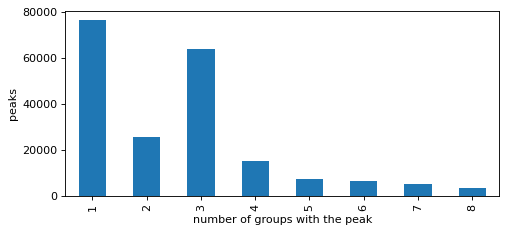

Kupffer           17046
Hepatocyte_PP     16857
HSC               15406
Hepatocyte_PC     10957
LSEC               9155
Hepatocyte_mid     3317
T_cell             1962
BEC                1933
Name: peaks unique to the group, dtype: int64

In [21]:
# one True/False column per group: was the peak called in that group? Their sum is the number of groups
n_groups = consensus.drop(columns="Peaks").sum(axis=1)
n_groups.value_counts().sort_index().plot.bar(figsize=(7, 3), xlabel="number of groups with the peak", ylabel="peaks")
plt.show()
consensus.drop(columns="Peaks")[n_groups == 1].sum().sort_values(ascending=False).rename("peaks unique to the group")

The largest category (about 38% of the peaks) is found in a single group, followed by peaks found in exactly three: those are the peaks shared by the three hepatocyte zones (PP, mid, PC), which differ far less from each other than from the other cell types. Kupffer cells, periportal hepatocytes and stellate cells have the most unique peaks.

The authors built their own consensus peaks (with pycisTopic, on more samples). How many of ours overlap theirs? Their regions are the rows of the count matrix they deposited on GEO.

In [22]:
import pyranges as pr

def to_ranges(names):
    """chr:start-end strings to a PyRanges object"""
    parts = pd.Series(names).str.extract(r"(?P<Chromosome>[^:]+):(?P<Start>\d+)-(?P<End>\d+)")
    return pr.PyRanges(parts.astype({"Start": int, "End": int}))

# the first column of the paper's count matrix holds the region names (chr:start-end); usecols=[0] reads only that
paper_regions = pd.read_csv(f"{SC}/raw/GSE218468_multiome_atac_counts.tsv.gz", sep="\t", usecols=[0]).iloc[:, 0]
ours = to_ranges(consensus["Peaks"])
theirs = to_ranges(paper_regions)
# overlap(): our regions that overlap at least one of theirs
shared = ours.overlap(theirs)
print(f"ours: {len(ours)}, paper: {len(theirs)}, ours overlapping the paper's: {len(shared)} ({100 * len(shared) / len(ours):.0f}%)")

ours: 203415, paper: 486888, ours overlapping the paper's: 189548 (93%)


More than 90% of our peaks overlap a region of the paper. The paper has more than twice as many regions: it was built from more samples, and so from more cells and more cell types.

## Step 6: The cell × peak matrix

Finally, we count for every cell the fragments in every consensus peak. This sparse matrix is the input of the next notebooks.

In [23]:
# counting_strategy="fragment": count each fragment once per peak (not its two Tn5 insertions)
peak_matrix = snap.pp.make_peak_matrix(data, use_rep=consensus["Peaks"].tolist(), counting_strategy="fragment")
peak_matrix.obs = data.obs[:].to_pandas().set_index(pd.Index(data.obs_names, name="barcode"))
print(peak_matrix)
print(f"{peak_matrix.X.nnz / (peak_matrix.n_obs * peak_matrix.n_vars):.2%} of the matrix is non-zero")

AnnData object with n_obs × n_vars = 11297 × 203415
    obs: 'sample', 'cell_type', 'zone', 'n_fragment', 'tsse', 'peak_group'
2.82% of the matrix is non-zero


Single-cell ATAC data are extremely sparse: about 97% of the entries are 0. Even in peaks, a cell usually has 0, 1 or 2 fragments, which is why the next notebooks use methods that share information across regions (topics in pycisTopic) or across cells (spectral embedding in SnapATAC2).

## Step 7: Saving the results

- `liver_peaks.h5ad`: the cell × peak matrix with all cell annotations (parts 3 and 4);
- `consensus_peaks.bed`: the consensus regions (part 2);
- `cells.tsv`: the selected cells with sample, cell type, zone and QC metrics (part 2).

In [24]:
peak_matrix.write("liver_peaks.h5ad", compression="gzip")
ours.df.to_csv("consensus_peaks.bed", sep="\t", header=False, index=False)
peak_matrix.obs[["sample", "cell_type", "zone", "n_fragment", "tsse"]].to_csv("cells.tsv", sep="\t")
for f in ["liver_peaks.h5ad", "consensus_peaks.bed", "cells.tsv"]:
    print(f, f"{os.path.getsize(f) / 1e6:.1f} MB")

liver_peaks.h5ad 131.0 MB
consensus_peaks.bed 4.9 MB
cells.tsv 0.8 MB


... storing 'sample' as categorical
... storing 'cell_type' as categorical
... storing 'zone' as categorical
... storing 'peak_group' as categorical


## Summary

| step | what we did | why |
|---|---|---|
| import | fragment files → one row per barcode | fragment files are the standard scATAC input |
| QC | fragments per cell, TSS enrichment, fragment sizes | separate real cells from empty droplets and damaged nuclei |
| doublets | Scrublet on a tile matrix | flags doublets, but also polyploid hepatocytes: interpret per cell type |
| annotation | RNA-based labels and zones, checked with gene activity | the labels we need for pseudobulks and DARs |
| pseudobulk peaks | MACS3 per cell type / zone | single cells are too sparse for peak calling |
| consensus | fixed-width iterative merge | one common set of regions, as in bulk ATAC-seq part 2 |
| peak matrix | fragments per cell and consensus peak | input for pycisTopic (part 2), SnapATAC2 (part 3) and DARs (part 4) |

## Exercises

1. How do the numbers of Step 3b change with stricter thresholds? Count, for each sample, how many barcodes pass `n_fragment >= 3000` and `tsse >= 10`, and how many of the paper's cells you would lose.
2. The `zone` column labels hepatocytes as periportal (`PP`), `mid` or pericentral (`PC`). Check these labels with gene activity: make a dot plot of the hepatocytes only (`gene_activity[gene_activity.obs["zone"] != ""]`), grouped by zone, for the pericentral markers *Cyp2e1*, *Glul*, *Oat* and the periportal markers *Cyp2f2*, *Hal*, *Sds* and *Cps1*. Do the labels make sense? Why does the `mid` group look the way it does?
3. Compare the RNA-based labels with the ATAC-based labels of the paper (column `cell_type_atac` of `annotations/cell_annotations.tsv`). For which cell types do the two disagree most?